In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN
)

from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Generate synthetic customer data

X, _ = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=1.0,
    random_state=42
)

# Convert the generated data into realistic-looking values
X = X * [10, 8] + [60, 50]

# Create DataFrame
df = pd.DataFrame(
    X,
    columns=["Annual_Income", "Spending_Score"]
)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (300, 2)


,Annual_Income,Spending_Score
0,-32.976887,101.789428
1,-36.987411,105.511739
2,43.133473,112.347540
3,-10.973084,3.749338
4,-48.764523,100.523493


In [ ]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Annual_Income   300 non-null    float64
 1   Spending_Score  300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB
None

Statistical Summary:
       Annual_Income  Spending_Score
count     300.000000      300.000000
mean       25.961632       72.762628
std        52.891542       49.805935
min       -53.099723      -21.354734
25%       -19.522365       40.551047
50%        12.918655       90.535957
75%        58.823941      114.635546
max       129.545374      141.820226


In [ ]:
print("\nFirst 10 Customers:")
print(df.head(10))


First 10 Customers:
   Annual_Income  Spending_Score
0     -32.976887      101.789428
1     -36.987411      105.511739
2      43.133473      112.347540
3     -10.973084        3.749338
4     -48.764523      100.523493
5      -0.219676       -6.320385
6     108.130598       68.867897
7      -4.666957       -9.550673
8      30.116281      120.629017
9      94.485753       71.037786


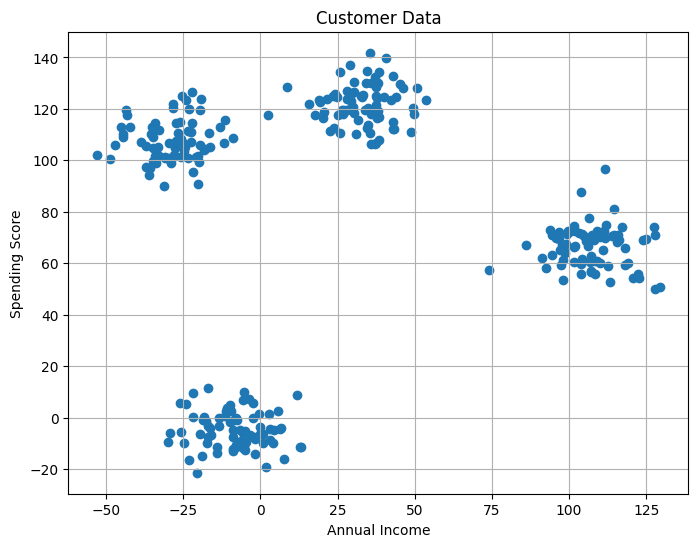

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"]
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Data")

plt.grid()

plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data created successfully!")
print(X_scaled[:5])

Scaled data created successfully!
[[-1.11618972  0.58377179]
 [-1.19214185  0.65863295]
 [ 0.32520384  0.79611099]
 [-0.6994772  -1.38795911]
 [-1.4151792   0.55831196]]


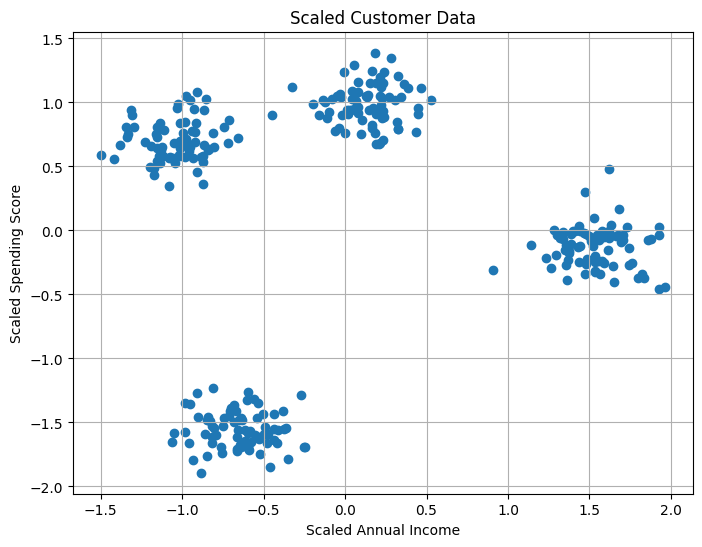

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1]
)

plt.xlabel("Scaled Annual Income")
plt.ylabel("Scaled Spending Score")

plt.title("Scaled Customer Data")

plt.grid()

plt.show()

In [ ]:
kmeans_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10
    ))
])

kmeans_pipeline.fit(X)

print("Pipeline training completed!")

Pipeline training completed!


In [ ]:
kmeans_labels = kmeans_pipeline.predict(X)

print("Cluster Labels:")
print(kmeans_labels[:20])

Cluster Labels:
[3 3 0 1 3 1 2 1 0 2 0 2 0 0 3 0 3 2 0 0]


In [ ]:
df["KMeans_Cluster"] = kmeans_labels

df.head()

,Annual_Income,Spending_Score,KMeans_Cluster
0,-32.976887,101.789428,3
1,-36.987411,105.511739,3
2,43.133473,112.347540,0
3,-10.973084,3.749338,1
4,-48.764523,100.523493,3


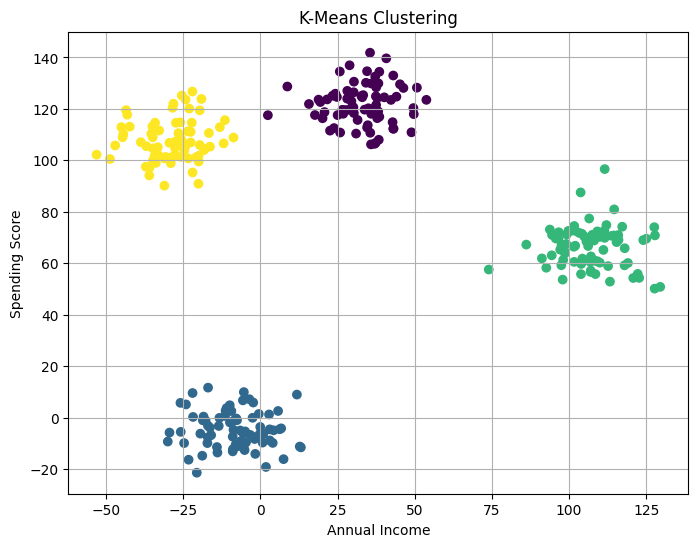

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans_labels
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.title("K-Means Clustering")

plt.grid()

plt.show()

In [ ]:
inertias = []

K_values = range(2, 11)

for k in K_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertias.append(model.inertia_)

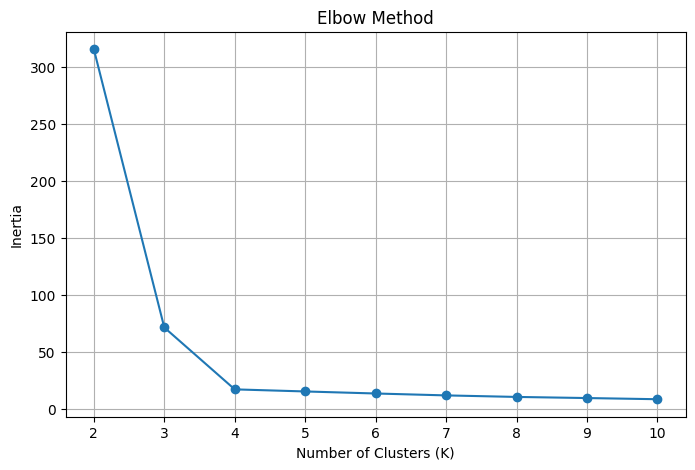

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    K_values,
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.title("Elbow Method")

plt.grid()

plt.show()

In [ ]:
silhouette_kmeans = silhouette_score(
    X_scaled,
    kmeans_labels
)

print("K-Means Silhouette Score:",
      silhouette_kmeans)

K-Means Silhouette Score: 0.7974739889632729


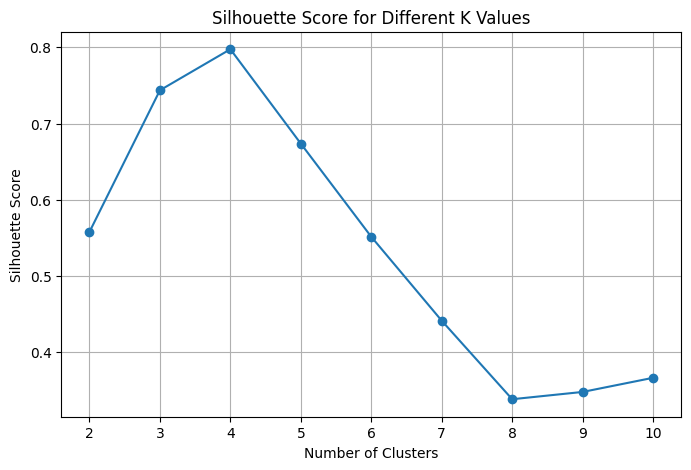

In [ ]:
silhouette_scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Score for Different K Values")

plt.grid()

plt.show()

In [ ]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=4
)

hierarchical_labels = hierarchical_model.fit_predict(
    X_scaled
)

print("Hierarchical Cluster Labels:")
print(hierarchical_labels[:20])

Hierarchical Cluster Labels:
[2 2 3 1 2 1 0 1 3 0 3 0 3 3 2 3 2 0 3 3]


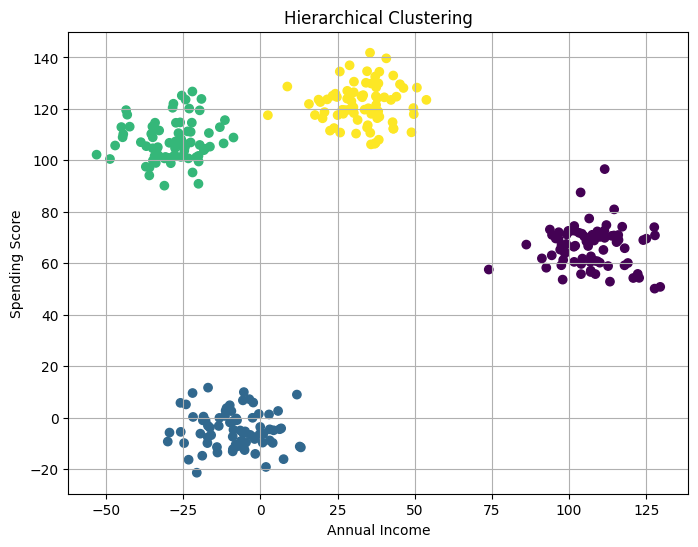

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=hierarchical_labels
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.title("Hierarchical Clustering")

plt.grid()

plt.show()

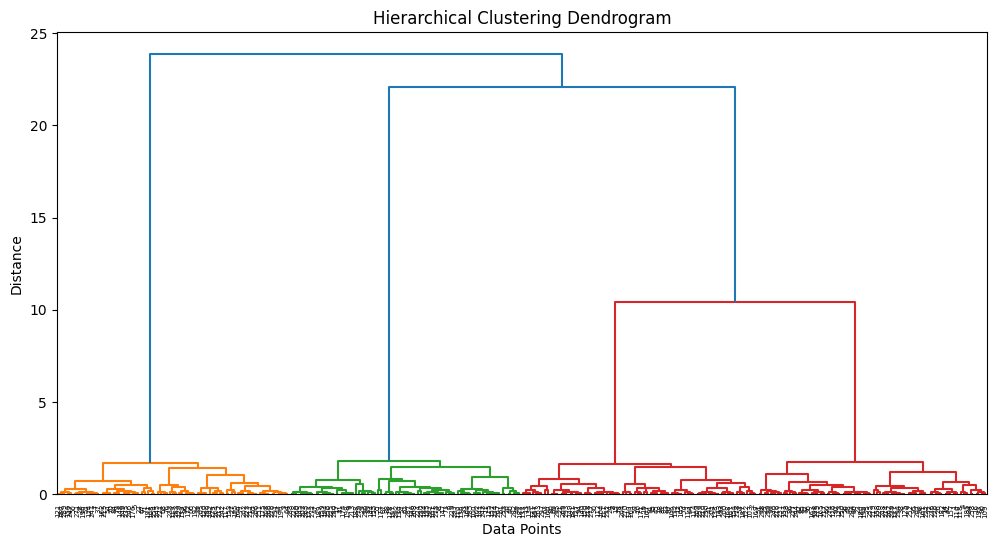

In [ ]:
plt.figure(figsize=(12, 6))

linkage_matrix = linkage(
    X_scaled,
    method="ward"
)

dendrogram(linkage_matrix)

plt.title("Hierarchical Clustering Dendrogram")

plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()

In [ ]:
silhouette_hierarchical = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print(
    "Hierarchical Clustering Silhouette Score:",
    silhouette_hierarchical
)

Hierarchical Clustering Silhouette Score: 0.7974739889632729


In [ ]:
dbscan_model = DBSCAN(
    eps=0.3,
    min_samples=5
)

dbscan_labels = dbscan_model.fit_predict(
    X_scaled
)

print("DBSCAN Labels:")
print(dbscan_labels[:30])

DBSCAN Labels:
[0 0 0 1 0 1 2 1 0 2 0 2 0 0 0 0 0 2 0 0 2 0 1 0 0 0 0 1 1 2]


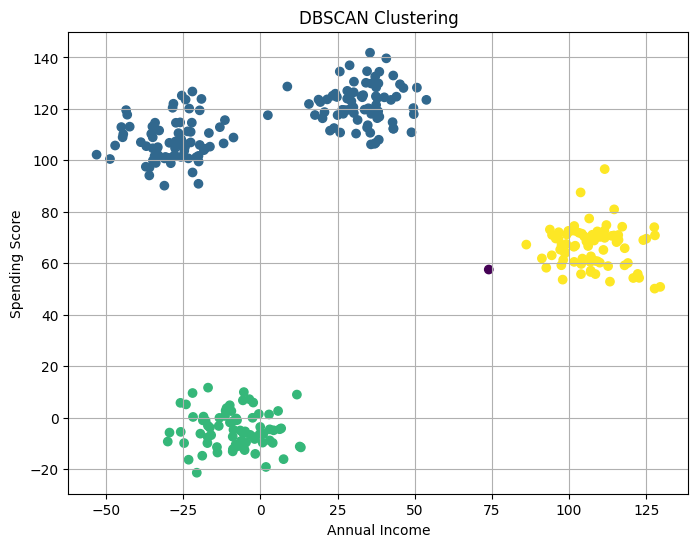

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=dbscan_labels
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.title("DBSCAN Clustering")

plt.grid()

plt.show()

In [ ]:
unique_labels = set(dbscan_labels)

print("Unique DBSCAN Labels:")
print(unique_labels)

n_clusters = len(
    unique_labels - {-1}
)

n_noise = list(dbscan_labels).count(-1)

print("\nNumber of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

Unique DBSCAN Labels:
{np.int64(0), np.int64(1), np.int64(2), np.int64(-1)}

Number of Clusters: 3
Number of Noise Points: 1


In [ ]:
dbscan_cluster_labels = set(dbscan_labels)

if len(dbscan_cluster_labels - {-1}) >= 2:

    # Remove noise points
    mask = dbscan_labels != -1

    score_dbscan = silhouette_score(
        X_scaled[mask],
        dbscan_labels[mask]
    )

    print(
        "DBSCAN Silhouette Score:",
        score_dbscan
    )

else:

    score_dbscan = np.nan

    print(
        "Silhouette Score cannot be calculated "
        "because DBSCAN found fewer than 2 clusters."
    )

DBSCAN Silhouette Score: 0.7447711507342999


In [ ]:
comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical",
        "DBSCAN"
    ],
    "Silhouette Score": [
        silhouette_kmeans,
        silhouette_hierarchical,
        score_dbscan
    ]
})

comparison

,Algorithm,Silhouette Score
0,K-Means,0.797474
1,Hierarchical,0.797474
2,DBSCAN,0.744771


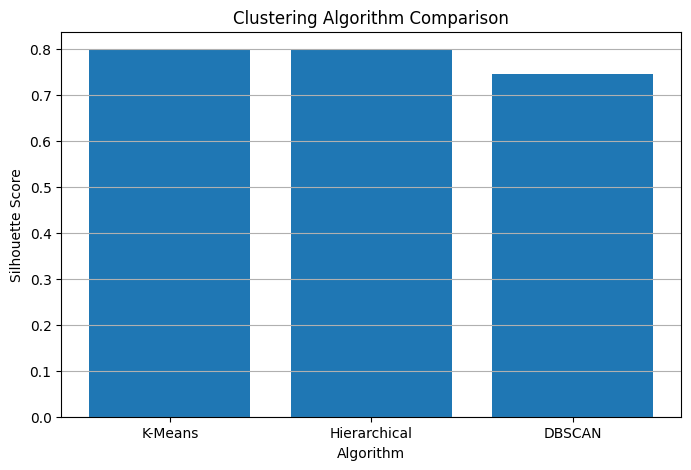

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Algorithm"],
    comparison["Silhouette Score"]
)

plt.xlabel("Algorithm")
plt.ylabel("Silhouette Score")

plt.title("Clustering Algorithm Comparison")

plt.grid(axis="y")

plt.show()

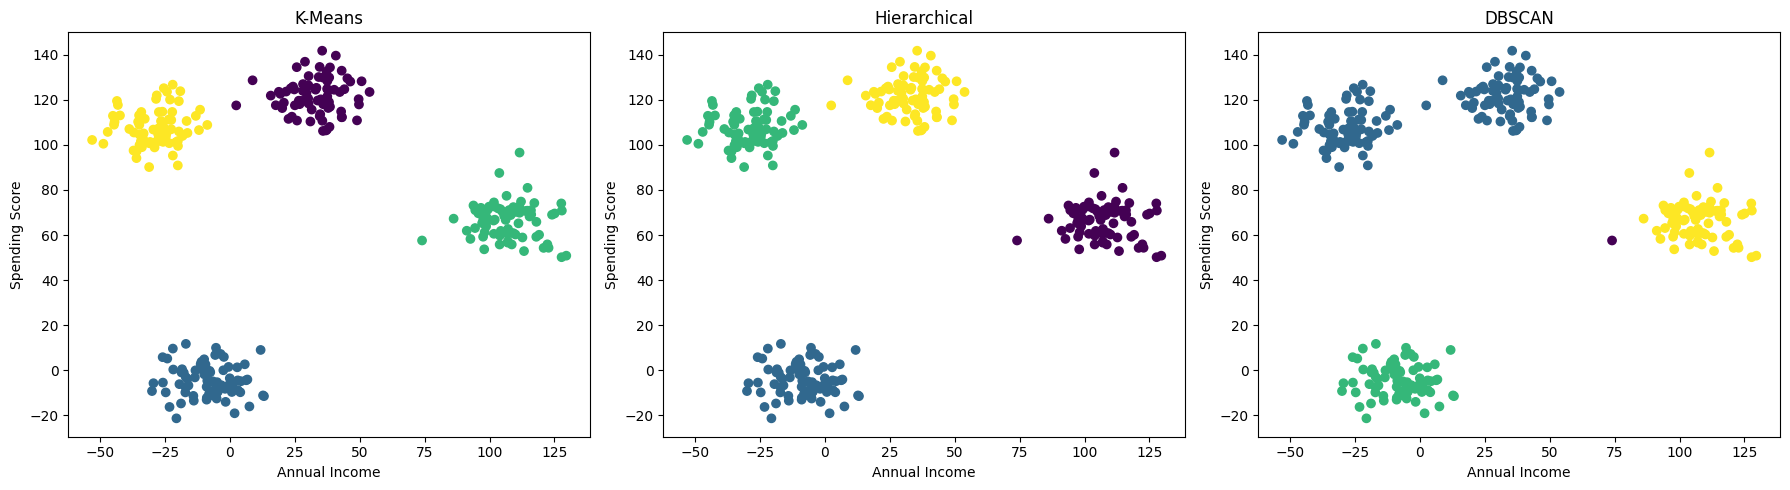

In [ ]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

# K-Means
axes[0].scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans_labels
)

axes[0].set_title("K-Means")
axes[0].set_xlabel("Annual Income")
axes[0].set_ylabel("Spending Score")

# Hierarchical
axes[1].scatter(
    X[:, 0],
    X[:, 1],
    c=hierarchical_labels
)

axes[1].set_title("Hierarchical")
axes[1].set_xlabel("Annual Income")
axes[1].set_ylabel("Spending Score")

# DBSCAN
axes[2].scatter(
    X[:, 0],
    X[:, 1],
    c=dbscan_labels
)

axes[2].set_title("DBSCAN")
axes[2].set_xlabel("Annual Income")
axes[2].set_ylabel("Spending Score")

plt.tight_layout()

plt.show()